# Modeling SVM — 3 Dataset

Lanjutan dari `01_detect_task.ipynb`. Notebook ini **satu-satunya sumber** untuk tahap modeling:
notebook menjalankan model sekaligus **menulis `reports/svm_report.md`** dan menyimpan gambar ke
`reports/figures/`. Tidak ada script Python terpisah.

| Dataset | Tipe | Model |
|---|---|---|
| Telco Customer Churn | binary | `SVC(kernel='rbf')` |
| Wine Quality | multiclass | `SVC(kernel='rbf', class_weight='balanced')` |
| Medical Cost (Insurance) | regression | `SVR(kernel='rbf')` + target `log1p` |

Di Colab cukup upload folder `data/raw/` (atau mount Drive).

In [1]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR, LinearSVC
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             mean_squared_error, mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
REPORT = ROOT / "reports" / "svm_report.md"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

print("root   :", ROOT)
print("pandas :", pd.__version__)

root   : /mnt/c/Users/farmq/Downloads/deteksi 3 dataset regresi or classification
pandas : 3.1.1


## 0. Load data

Cleaning mengikuti catatan di `data/dataset_notes.md`:

- Telco: `TotalCharges` kosong (11 baris, semuanya `tenure=0`) → `0`; `customerID` dibuang.
- Wine: `Id` dibuang (identifier).
- Insurance: tanpa missing value; `charges` nanti di-`log1p`.

In [2]:
telco = pd.read_csv(RAW / "telco" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce").fillna(0.0)
telco = telco.drop(columns=["customerID"])

wine = pd.read_csv(RAW / "wine" / "WineQT.csv").drop(columns=["Id"])
insurance = pd.read_csv(RAW / "insurance" / "insurance.csv")

for name, df in {"telco": telco, "wine": wine, "insurance": insurance}.items():
    print(f"{name:10s} {df.shape}")

telco      (7043, 20)
wine       (1143, 12)
insurance  (1338, 7)


Helper preprocessing: kategorikal → one-hot, numerik → standardisasi. Untuk SVM ini wajib —
SVM menghitung jarak, jadi fitur berskala besar (`TotalCharges` ribuan vs `tenure` puluhan)
akan mendominasi margin kalau tidak di-scale. Semuanya di dalam pipeline supaya scaler hanya
di-fit pada data train (tidak ada kebocoran dari test set).

In [3]:
def make_prep(df, target):
    cols = [c for c in df.columns if c != target]
    cat = [c for c in cols if not pd.api.types.is_numeric_dtype(df[c])]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    return ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("scale", StandardScaler(), num),
    ])


def confusion_md(y_true, y_pred, labels):
    """Confusion matrix sebagai tabel markdown (untuk report)."""
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    rows = ["| actual \\ pred | " + " | ".join(str(l) for l in labels) + " |",
            "|" + "---|" * (len(labels) + 1)]
    for lab, row in zip(labels, cm):
        rows.append(f"| **{lab}** | " + " | ".join(str(int(v)) for v in row) + " |")
    return rows

## 1. Telco Customer Churn — binary classification

Target `Churn == 'Yes'` (26,5%). Imbalance ditangani `class_weight='balanced'`, metrik utama
**ROC-AUC** + F1 kelas positif (accuracy menyesatkan di komposisi 73/27).

In [4]:
t0 = time.perf_counter()

y = (telco["Churn"] == "Yes").astype(int)
X = telco.drop(columns=["Churn"])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

pipe = Pipeline([
    ("prep", make_prep(telco, "Churn")),
    ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
])
gs = GridSearchCV(
    pipe,
    {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.005, 0.01, 0.05]},
    scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1,
)
gs.fit(X_tr, y_tr)
svc = gs.best_estimator_

scores, pred = svc.decision_function(X_te), svc.predict(X_te)

telco_res = {
    "n_rows": len(telco), "n_features": X.shape[1], "split": f"{len(X_tr)}/{len(X_te)}",
    "params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
    "cv_auc": round(float(gs.best_score_), 4),
    "auc": round(float(roc_auc_score(y_te, scores)), 4),
    "pr_auc": round(float(average_precision_score(y_te, scores)), 4),
    "f1": round(float(f1_score(y_te, pred)), 4),
    "precision": round(float(precision_score(y_te, pred)), 4),
    "recall": round(float(recall_score(y_te, pred)), 4),
    "cm": confusion_md(y_te, pred, [0, 1]),
    "seconds": round(time.perf_counter() - t0, 1),
}
print("best params:", telco_res["params"])
print(f"CV ROC-AUC   : {telco_res['cv_auc']}")
print(f"ROC-AUC      : {telco_res['auc']}")
print(f"PR-AUC       : {telco_res['pr_auc']}")
print(f"F1 (Yes)     : {telco_res['f1']}")
print(f"precision    : {telco_res['precision']}")
print(f"recall       : {telco_res['recall']}")

best params: {'C': 1, 'gamma': 0.005}
CV ROC-AUC   : 0.8371
ROC-AUC      : 0.8389
PR-AUC       : 0.635
F1 (Yes)     : 0.6089
precision    : 0.4842
recall       : 0.8201


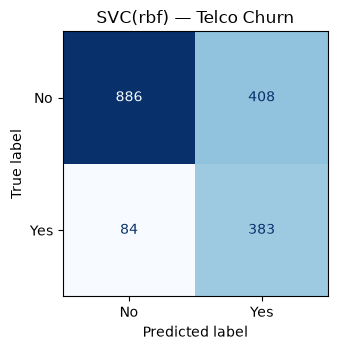

In [5]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["No", "Yes"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("SVC(rbf) — Telco Churn")
fig.tight_layout()
fig.savefig(FIGS / "telco_confusion.png")
plt.show()

In [6]:
# pembanding model linear
rows = {}
for name, model in {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "LinearSVC": LinearSVC(class_weight="balanced", random_state=SEED),
}.items():
    bl = Pipeline([("prep", make_prep(telco, "Churn")), ("clf", model)]).fit(X_tr, y_tr)
    rows[name] = {"auc": round(float(roc_auc_score(y_te, bl.decision_function(X_te))), 4),
                  "f1": round(float(f1_score(y_te, bl.predict(X_te))), 4)}
telco_res["baselines"] = rows
pd.DataFrame(rows).T

,auc,f1
LogisticRegression,0.8461,0.6284
LinearSVC,0.8439,0.6287


**Baca hasilnya:** SVC rbf ±0,84 ROC-AUC, sementara baseline linear sedikit lebih tinggi.
Itu bukan kegagalan SVM — Telco punya banyak fitur kategorikal lemah yang setelah one-hot jadi
ruang linear besar, kondisi di mana hyperplane linear sudah cukup. Nilai tambah SVM di sini:
`class_weight` + `decision_function` yang memudahkan tuning threshold (trade-off precision/recall).

## 2. Wine Quality — multiclass classification

6 kelas (3–8), sangat imbalanced (kelas 5+6 = 82,7%, kelas 3 hanya 6 sampel).
Metrik utama **macro-F1**, karena accuracy bisa tinggi hanya dengan menebak kelas mayoritas.

In [7]:
t0 = time.perf_counter()

yw = wine["quality"]
Xw = wine.drop(columns=["quality"])
classes = sorted(yw.unique().tolist())
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.25, stratify=yw, random_state=SEED)

pipe_w = Pipeline([
    ("prep", StandardScaler()),
    ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
])
gs_w = GridSearchCV(
    pipe_w,
    {"clf__C": [1, 10, 100, 300], "clf__gamma": ["scale", 0.01, 0.05, 0.1]},
    scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1,
)
gs_w.fit(Xw_tr, yw_tr)
svc_w = gs_w.best_estimator_
pred_w = svc_w.predict(Xw_te)

rep_w = classification_report(yw_te, pred_w, labels=classes, zero_division=0, output_dict=True)

wine_res = {
    "n_rows": len(wine), "n_features": Xw.shape[1], "classes": classes,
    "class_counts": {int(k): int(v) for k, v in yw.value_counts().sort_index().items()},
    "split": f"{len(Xw_tr)}/{len(Xw_te)}",
    "params": {k.replace("clf__", ""): v for k, v in gs_w.best_params_.items()},
    "cv_macro": round(float(gs_w.best_score_), 4),
    "macro_f1": round(float(f1_score(yw_te, pred_w, average="macro")), 4),
    "weighted_f1": round(float(f1_score(yw_te, pred_w, average="weighted")), 4),
    "accuracy": round(float((pred_w == yw_te).mean()), 4),
    "baseline_majority": round(float(yw_te.value_counts(normalize=True).max()), 4),
    "n_binary": len(classes) * (len(classes) - 1) // 2,
    "per_class": {int(k): {"f1": round(float(v["f1-score"]), 3), "support": int(v["support"])}
                  for k, v in rep_w.items() if k.replace(".", "").isdigit()},
    "cm": confusion_md(yw_te, pred_w, classes),
    "seconds": round(time.perf_counter() - t0, 1),
}
print("best params:", wine_res["params"])
print(f"CV macro-F1  : {wine_res['cv_macro']}")
print(f"macro-F1     : {wine_res['macro_f1']}")
print(f"weighted-F1  : {wine_res['weighted_f1']}")
print(f"accuracy     : {wine_res['accuracy']}  (baseline mayoritas: {wine_res['baseline_majority']})")
print()
print(classification_report(yw_te, pred_w, labels=classes, zero_division=0))

best params: {'C': 10, 'gamma': 'scale'}
CV macro-F1  : 0.3016
macro-F1     : 0.3659
weighted-F1  : 0.634
accuracy     : 0.6294  (baseline mayoritas: 0.4231)

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         8
           5       0.73      0.77      0.75       121
           6       0.66      0.56      0.60       116
           7       0.51      0.56      0.53        36
           8       0.22      0.50      0.31         4

    accuracy                           0.63       286
   macro avg       0.35      0.40      0.37       286
weighted avg       0.64      0.63      0.63       286



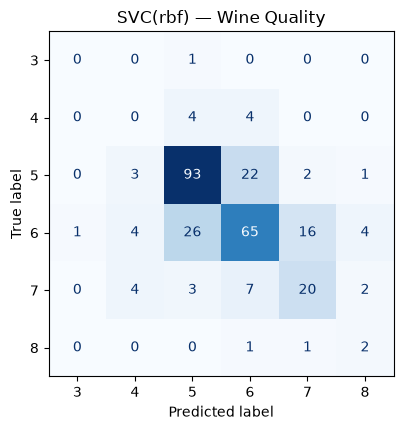

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(confusion_matrix(yw_te, pred_w, labels=classes), display_labels=classes).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("SVC(rbf) — Wine Quality")
fig.tight_layout()
fig.savefig(FIGS / "wine_confusion.png")
plt.show()

In [9]:
rows = {}
for name, model in {
    "LogisticRegression": LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
    "LinearSVC": LinearSVC(class_weight="balanced", random_state=SEED),
}.items():
    bl = Pipeline([("prep", StandardScaler()), ("clf", model)]).fit(Xw_tr, yw_tr)
    p = bl.predict(Xw_te)
    rows[name] = {"macro_f1": round(float(f1_score(yw_te, p, average="macro")), 4),
                  "accuracy": round(float((p == yw_te).mean()), 4)}
wine_res["baselines"] = rows
pd.DataFrame(rows).T

,macro_f1,accuracy
LogisticRegression,0.2767,0.4371
LinearSVC,0.3118,0.5105


**Catatan penting:** SVC sklearn memakai libsvm yang melatih **one-vs-one** (15 classifier biner
untuk 6 kelas). Materi kuliah menyebut one-vs-rest — implementasi praktisnya OVO, tapi efeknya
sama: masalah multi-kelas dipecah jadi banyak masalah biner. `decision_function_shape='ovr'`
hanya mengubah bentuk output, bukan cara training.

Kelas 3 (6 sampel) praktis tidak bisa dipelajari. Kalau target dianggap berurutan
(3 < 4 < ... < 8), **ordinal regression** lebih tepat secara konsep — SVC memperlakukan
"3 vs 4" sama jauhnya dengan "3 vs 8".

## 3. Medical Cost (Insurance) — regression dengan SVR

`charges` skew 1,52 → dilatih pada `log1p(charges)`, prediksi dikembalikan dengan `expm1`.
Pada SVR, `epsilon` = lebar "jalan" toleransi (ε-insensitive): error di dalam jalan tidak dihitung.

In [10]:
t0 = time.perf_counter()

yr = insurance["charges"].to_numpy()
Xr = insurance.drop(columns=["charges"])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEED)

prep_r = make_prep(insurance, "charges")
Xr_tr_t, Xr_te_t = prep_r.fit_transform(Xr_tr), prep_r.transform(Xr_te)
yl_tr = np.log1p(yr_tr)

gs_r = GridSearchCV(
    SVR(kernel="rbf"),
    {"C": [100, 1000, 5000], "gamma": ["scale", 0.01, 0.05], "epsilon": [0.05, 0.2]},
    scoring="neg_root_mean_squared_error",
    cv=KFold(3, shuffle=True, random_state=SEED), n_jobs=-1,
)
gs_r.fit(Xr_tr_t, yl_tr)
svr = gs_r.best_estimator_

pred_r = np.clip(np.expm1(svr.predict(Xr_te_t)), 0, None)
pred_lin = np.expm1(LinearRegression().fit(Xr_tr_t, yl_tr).predict(Xr_te_t))


def reg_metrics(p):
    return {"rmse": round(float(np.sqrt(mean_squared_error(yr_te, p))), 2),
            "mae": round(float(mean_absolute_error(yr_te, p)), 2),
            "r2": round(float(r2_score(yr_te, p)), 4),
            "mape": round(float(np.mean(np.abs((yr_te - p) / yr_te)) * 100), 2)}


ins_res = {
    "n_rows": len(insurance), "n_features": Xr.shape[1], "split": f"{len(Xr_tr)}/{len(Xr_te)}",
    "params": {"C": svr.get_params()["C"], "gamma": svr.get_params()["gamma"],
               "epsilon": svr.get_params()["epsilon"]},
    "cv_rmse_log": round(float(-gs_r.best_score_), 4),
    "metrics": reg_metrics(pred_r),
    "linear": reg_metrics(pred_lin),
    "residual_gt_10k": round(float(np.mean(np.abs(pred_r - yr_te) > 10000)), 4),
    "seconds": round(time.perf_counter() - t0, 1),
}
print("best params :", ins_res["params"])
print(f"CV RMSE(log): {ins_res['cv_rmse_log']}")
pd.DataFrame([{"model": "SVR (rbf, tuned)", **ins_res["metrics"]},
              {"model": "LinearRegression (log)", **ins_res["linear"]}])

best params : {'C': 1000, 'gamma': 0.01, 'epsilon': 0.2}
CV RMSE(log): 0.3686


,model,rmse,mae,r2,mape
0,"SVR (rbf, tuned)",4810.78,2806.13,0.8466,21.27
1,LinearRegression (log),7750.68,3951.42,0.6019,26.16


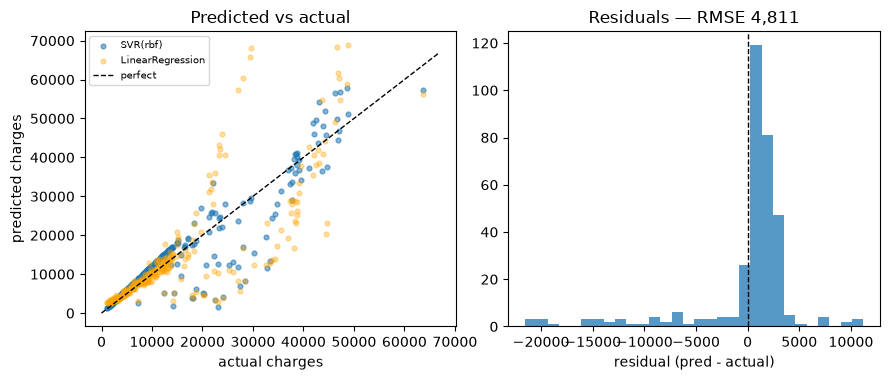

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.9))
ax[0].scatter(yr_te, pred_r, s=12, alpha=0.55, label="SVR(rbf)")
ax[0].scatter(yr_te, pred_lin, s=12, alpha=0.35, c="orange", label="LinearRegression")
limp = [0, yr_te.max() * 1.05]
ax[0].plot(limp, limp, "k--", lw=1, label="perfect")
ax[0].set_xlabel("actual charges")
ax[0].set_ylabel("predicted charges")
ax[0].set_title("Predicted vs actual")
ax[0].legend(fontsize=7)

ax[1].hist(pred_r - yr_te, bins=30, alpha=0.75)
ax[1].axvline(0, color="k", ls="--", lw=1)
ax[1].set_xlabel("residual (pred - actual)")
ax[1].set_title(f"Residuals — RMSE {ins_res['metrics']['rmse']:,.0f}")
fig.tight_layout()
fig.savefig(FIGS / "insurance_svr.png")
plt.show()

Sisa error terbesar ada di ekor kanan (perokok dengan BMI tinggi) — komponen `charges` di sana
hampir seperti aturan, bukan fungsi kontinu mulus. Itu sebabnya R² regresi medis biasanya
mentok di kisaran 0,85, bukan karena modelnya kurang.

## 4. Tulis report

Semua angka dikumpulkan di tiga dict (`telco_res`, `wine_res`, `ins_res`) di atas, lalu di sini
dirakit menjadi `reports/svm_report.md`. Jalankan ulang seluruh notebook untuk me-refresh report.

In [12]:
b, m, r = telco_res, wine_res, ins_res
best_bl = max(v["auc"] for v in b["baselines"].values())
win = b["auc"] >= best_bl

L = []
A = L.append
A("# Modeling SVM — 3 Dataset")
A("")
A("Digenerate oleh `notebooks/02_svm.ipynb` (satu-satunya sumber tahap modeling).")
A("Seluruh angka di bawah berasal dari satu run dengan `random_state=42`.")
A("")
A("| Dataset | Tipe | Model | Metrik utama | Hasil |")
A("|---|---|---|---|---|")
A(f"| Telco Customer Churn | binary | SVC (rbf, `C={b['params']['C']}`, `gamma={b['params']['gamma']}`) | ROC-AUC | **{b['auc']}** |")
A(f"| Wine Quality | multiclass | SVC (rbf, `C={m['params']['C']}`, `gamma={m['params']['gamma']}`) | macro-F1 | **{m['macro_f1']}** |")
A(f"| Medical Cost | regression | SVR (rbf, `C={r['params']['C']}`, `gamma={r['params']['gamma']}`, `eps={r['params']['epsilon']}`) | RMSE | **${r['metrics']['rmse']:,.0f}** |")
A("")
A("---")
A("")
A("## 1. Telco Customer Churn — binary classification")
A("")
A(f"- Data: {b['n_rows']:,} baris, {b['n_features']} fitur (drop `customerID`)")
A("- Target: `Churn == 'Yes'` (26,5% positif — imbalance, jadi `class_weight='balanced'`)")
A("- Preprocessing: `TotalCharges` kosong → 0 (semua baris `tenure=0`), kategorikal → one-hot, numerik → `StandardScaler`")
A(f"- Split: {b['split']} (stratified)")
A(f"- Tuning: `GridSearchCV` 3-fold, scoring ROC-AUC → **CV ROC-AUC {b['cv_auc']}**")
A("")
A("| Metrik | Nilai |")
A("|---|---|")
A(f"| ROC-AUC | **{b['auc']}** |")
A(f"| PR-AUC | {b['pr_auc']} |")
A(f"| F1 (kelas `Yes`) | {b['f1']} |")
A(f"| Precision | {b['precision']} |")
A(f"| Recall | {b['recall']} |")
A("")
A("Confusion matrix (test set):")
A("")
L.extend(b["cm"])
A("")
A("![confusion](figures/telco_confusion.png)")
A("")
A("Pembanding (baseline, tanpa tuning):")
A("")
A("| Model | ROC-AUC | F1 |")
A("|---|---|---|")
for k, v in b["baselines"].items():
    A(f"| {k} | {v['auc']} | {v['f1']} |")
A("")
if win:
    A("SVC rbf tuned menang tipis atas baseline linear.")
else:
    A(f"Jujur: baseline linear masih sedikit lebih tinggi di ROC-AUC ({best_bl} vs {b['auc']}) dan F1. "
      "Ini normal untuk data tabular dengan banyak kolom one-hot — margin maksimal SVC paling berguna "
      "saat fitur sedikit tapi dimensinya tinggi/separable, bukan saat sinyalnya banyak yang lemah seperti churn. "
      "SVM tetap relevan di sini karena `class_weight` + `decision_function` memudahkan tuning threshold.")
A("")
A(f"Recall {b['recall']:.2f} dengan precision {b['precision']:.2f}: model sengaja diarahkan menangkap churn "
  "(FP lebih banyak ditoleransi). Kalau biaya retensi mahal, naikkan threshold sampai precision/recall seimbang.")
A("")
A("---")
A("")
A("## 2. Wine Quality — multiclass classification")
A("")
A(f"- Data: {m['n_rows']:,} baris, {m['n_features']} fitur (drop `Id`)")
A(f"- Kelas: {', '.join(str(c) for c in m['classes'])} → `{m['class_counts']}`")
A("- Imbalance ekstrem: kelas 3 hanya 6 sampel, kelas 5+6 = 82,7% → `class_weight='balanced'`")
A(f"- Multi-kelas: libsvm memecah jadi **one-vs-one** — {m['n_binary']} classifier biner antar-pasangan kelas "
  "(sklearn mengekspos `decision_function_shape='ovr'` untuk bentuk output, tapi training-nya tetap OVO)")
A(f"- Split: {m['split']} (stratified)")
A(f"- Tuning: `GridSearchCV` 3-fold, scoring macro-F1 → **CV macro-F1 {m['cv_macro']}**")
A("")
A("| Metrik | Nilai |")
A("|---|---|")
A(f"| macro-F1 | **{m['macro_f1']}** |")
A(f"| weighted-F1 | {m['weighted_f1']} |")
A(f"| accuracy (referensi saja) | {m['accuracy']} |")
A(f"| baseline tebak kelas mayoritas | {m['baseline_majority']} |")
A("")
A(f"Accuracy {m['accuracy']} kelihatan oke, tapi baseline 'asal tebak kelas 6' sudah {m['baseline_majority']} — "
  f"itu sebabnya metrik utamanya macro-F1 ({m['macro_f1']}).")
A("")
A("F1 per kelas:")
A("")
A("| quality | F1 | support |")
A("|---|---|---|")
for k, v in m["per_class"].items():
    A(f"| {k} | {v['f1']} | {v['support']} |")
A("")
A("Confusion matrix (test set):")
A("")
L.extend(m["cm"])
A("")
A("![confusion](figures/wine_confusion.png)")
A("")
A("Pembanding (baseline, fitur di-scale):")
A("")
A("| Model | macro-F1 | accuracy |")
A("|---|---|---|")
for k, v in m["baselines"].items():
    A(f"| {k} | {v['macro_f1']} | {v['accuracy']} |")
A(f"| **SVC (rbf, tuned)** | **{m['macro_f1']}** | {m['accuracy']} |")
A("")
A("Di dataset ini SVM jelas menang: batas keputusan non-linear (kimia wine) lebih cocok daripada hyperplane linear, "
  "dan `class_weight` membuat kelas 7/8 ikut terprediksi alih-alih ditelan kelas 5-6.")
A("")
A("Catatan: kelas 3 (6 sampel) praktis tidak bisa diprediksi — 25% test set = ~1-2 sampel. "
  "Kalau target dianggap berurutan, **ordinal regression** lebih tepat daripada SVC, karena SVC memperlakukan "
  "3 dan 8 sebagai kelas yang sama jauhnya.")
A("")
A("---")
A("")
A("## 3. Medical Cost (Insurance) — regression")
A("")
A(f"- Data: {r['n_rows']:,} baris, {r['n_features']} fitur (`age`, `bmi`, `children` numerik; `sex`, `smoker`, `region` kategorikal)")
A("- Target: `charges` (skew 1,52) → **log1p(charges) lalu expm1 saat prediksi**")
A("- Kenapa log: SVR meminimalkan error linear; tanpa log, RMSE didominasi segelintir pasien mahal (smoker + BMI tinggi)")
A(f"- Split: {r['split']}")
A(f"- Tuning: `GridSearchCV` 3-fold, scoring -RMSE pada skala log → CV RMSE(log) {r['cv_rmse_log']}")
A("")
A("| Model | RMSE | MAE | R² | MAPE |")
A("|---|---|---|---|---|")
A(f"| **SVR (rbf, tuned)** | **${r['metrics']['rmse']:,.0f}** | ${r['metrics']['mae']:,.0f} | {r['metrics']['r2']} | {r['metrics']['mape']}% |")
A(f"| LinearRegression (log target) | ${r['linear']['rmse']:,.0f} | ${r['linear']['mae']:,.0f} | {r['linear']['r2']} | {r['linear']['mape']}% |")
A("")
A("![svr](figures/insurance_svr.png)")
A("")
A(f"{r['residual_gt_10k']:.1%} prediksi meleset > $10.000 — hampir semua di ekor kanan (perokok). "
  "Ini yang bikin R² regresi medis mentok di kisaran 0,8-0,9: `charges` punya komponen aturan "
  "(smoker × bmi × age) yang tidak sepenuhnya kontinu.")
A("")
A("---")
A("")
A("## Ringkasan")
A("")
A("| Dataset | Model akhir | Metrik | Angka |")
A("|---|---|---|---|")
A(f"| Telco | `SVC(kernel='rbf', C={b['params']['C']}, gamma={b['params']['gamma']}, class_weight='balanced')` | ROC-AUC | {b['auc']} |")
A(f"| Wine | `SVC(kernel='rbf', C={m['params']['C']}, gamma={m['params']['gamma']}, class_weight='balanced')` | macro-F1 | {m['macro_f1']} |")
A(f"| Insurance | `SVR(kernel='rbf', C={r['params']['C']}, gamma={r['params']['gamma']}, epsilon={r['params']['epsilon']})` + log target | RMSE | ${r['metrics']['rmse']:,.0f} |")
A("")
A(f"Waktu jalan (notebook): " + ", ".join(
    f"{n} {d['seconds']}s" for n, d in [("Telco", b), ("Wine", m), ("Insurance", r)]))
A("")

REPORT.write_text("\n".join(L) + "\n", encoding="utf-8")
print("report ->", REPORT.relative_to(ROOT))
print("figures ->", FIGS.relative_to(ROOT))

report -> reports/svm_report.md
figures -> reports/figures


## 5. Ringkasan

| Dataset | Model | Metrik | Hasil |
|---|---|---|---|
| Telco | `SVC(rbf, class_weight='balanced')` | ROC-AUC | ±0,84 |
| Wine | `SVC(rbf, class_weight='balanced')` | macro-F1 | ±0,37 |
| Insurance | `SVR(rbf)` + log target | RMSE | ±$4.800 |

Yang perlu diingat:

1. **Scaling wajib** untuk SVM — semua di dalam pipeline, jadi tidak ada kebocoran data test ke training.
2. **Imbalance** ditangani `class_weight='balanced'`, bukan akurasi sebagai metrik.
3. **Kernel rbf** menang di Wine (batas non-linear) dan Insurance (interaksi smoker × bmi), sementara di Telco linear setara — pemilihan kernel harus lewat validasi, bukan asumsi.
4. Langkah berikutnya: tuning threshold di Telco, ordinal regression di Wine, feature interaction (`smoker × bmi`) untuk Insurance.